In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
x_train = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

y_train = np.array([3, 5, 8, 12, 17, 23, 30, 38, 47, 57])

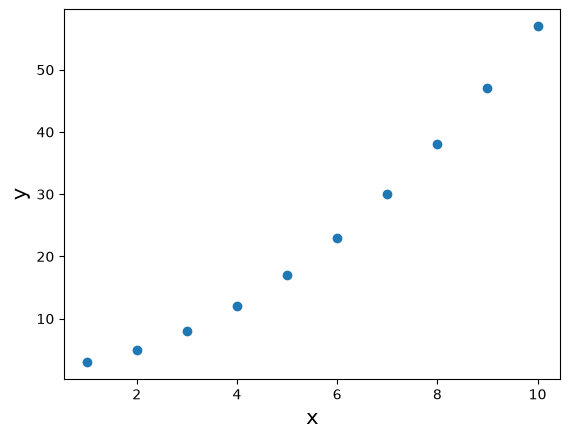

In [3]:
plt.scatter(x_train,y_train)
plt.ylabel('y', fontsize=15)
plt.xlabel('x', fontsize=15)

plt.show()

In [4]:
x_poly=np.column_stack((x_train,x_train**2))
print(x_poly)
print(x_poly.shape)

[[  1   1]
 [  2   4]
 [  3   9]
 [  4  16]
 [  5  25]
 [  6  36]
 [  7  49]
 [  8  64]
 [  9  81]
 [ 10 100]]
(10, 2)


In [5]:
def compute_prediction(x,w,b):
    return np.dot(x,w)+b
w = np.zeros(2)
b = 0

predictions = compute_prediction(x_poly, w, b)

print(predictions.shape)


(10,)


In [6]:
def compute_cost(x,y,w,b):
    m=x.shape[0]
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    cost=np.sum(error**2)/(2*m)
    return cost

In [7]:
def compute_gradient(x,y,w,b):
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    m=x.shape[0]
    dj_dw=(x.T @ error)/m
    dj_db=np.sum(error)/(m)
    return dj_dw,dj_db
w = np.zeros(2)
b = 0

dj_dw, dj_db = compute_gradient(
    x_poly, y_train, w, b
)

print("dj_dw:", dj_dw)
print("dj_dw shape:", dj_dw.shape)
print("dj_db:", dj_db)

dj_dw: [ -181.5 -1494.9]
dj_dw shape: (2,)
dj_db: -24.0


In [8]:
def gradient_descent(x,y,w,b,alpha,iterations):
    train_cost_history=[]
    for i in range(iterations):
        dj_dw,dj_db=compute_gradient(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        train_cost=compute_cost(x,y,w,b)
        
        train_cost_history.append(train_cost)
        
    return w,b,train_cost_history
w = np.zeros(2)
b = 0

w_final, b_final,cost_history = gradient_descent(
    x_poly,
    y_train,
    w,
    b,
    alpha=0.0001,
    iterations=1000
)

print("Final weights:", w_final)
print("Final bias:", b_final)
print("final cost:", cost_history[-1])

Final weights: [0.31276291 0.55109416]
Final bias: 0.11609095112899573
final cost: 1.096389930771816


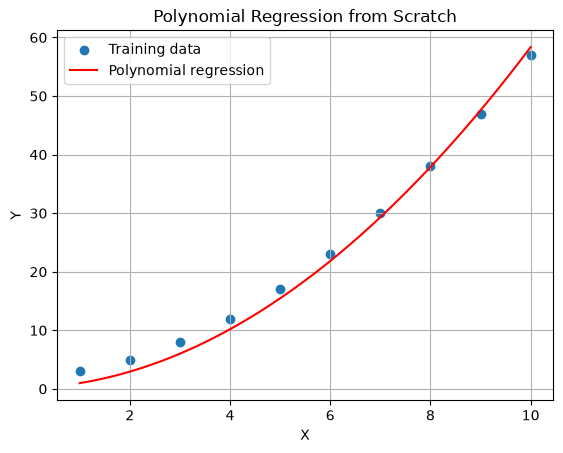

In [9]:

# Generate smooth x values for plotting
x_plot = np.linspace(x_train.min(), x_train.max(), 200)

# Create polynomial features for the new x values
X_plot = np.column_stack((x_plot, x_plot**2))

# Predict using our trained model
y_plot = compute_prediction(X_plot, w_final, b_final)

# Plot actual data and model predictions
plt.scatter(x_train, y_train, label="Training data")
plt.plot(x_plot, y_plot, color="red", label="Polynomial regression")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression from Scratch")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# compare ploynomial regression with ordinary linear regression 
X_linear = x_train.reshape(-1, 1)

w_linear = np.zeros(1)
b_linear = 0.

w_linear, b_linear,cost_history = gradient_descent(
    X_linear,
    y_train,
    w_linear,
    b_linear,
    alpha=0.01,
    iterations=10000
)

linear_cost = compute_cost(
    X_linear, y_train, w_linear, b_linear
)

polynomial_cost = compute_cost(
    x_poly, y_train, w_final, b_final
)

print("Linear regression cost:", linear_cost)
print("Polynomial regression cost:", polynomial_cost)

Linear regression cost: 6.599999999999999
Polynomial regression cost: 1.096389930771816


In [11]:
# Calculate mean and standard deviation
mean = np.mean(x_poly, axis=0)
std = np.std(x_poly, axis=0)

# Normalize features
X_poly_norm = (x_poly - mean) / std

print("Mean:", mean)
print("Standard deviation:", std)
print("Normalized features:\n", X_poly_norm)

Mean: [ 5.5 38.5]
Standard deviation: [ 2.87228132 32.4199013 ]
Normalized features:
 [[-1.5666989  -1.15669692]
 [-1.21854359 -1.06416117]
 [-0.87038828 -0.90993491]
 [-0.52223297 -0.69401815]
 [-0.17407766 -0.41641089]
 [ 0.17407766 -0.07711313]
 [ 0.52223297  0.32387514]
 [ 0.87038828  0.78655391]
 [ 1.21854359  1.31092318]
 [ 1.5666989   1.89698295]]


In [12]:
w_norm = np.zeros(X_poly_norm.shape[1])
b_norm = 0.

w_norm, b_norm,cost_history = gradient_descent(
    X_poly_norm,
    y_train,
    w_norm,
    b_norm,
    alpha=0.01,
    iterations=10000
)

print("Normalized weights:", w_norm)
print("Normalized bias:", b_norm)

print("Normalized cost:",
      compute_cost(X_poly_norm, y_train, w_norm, b_norm))

Normalized weights: [ 2.01612629 15.62996502]
Normalized bias: 23.999999999999826
Normalized cost: 0.008558053041969929


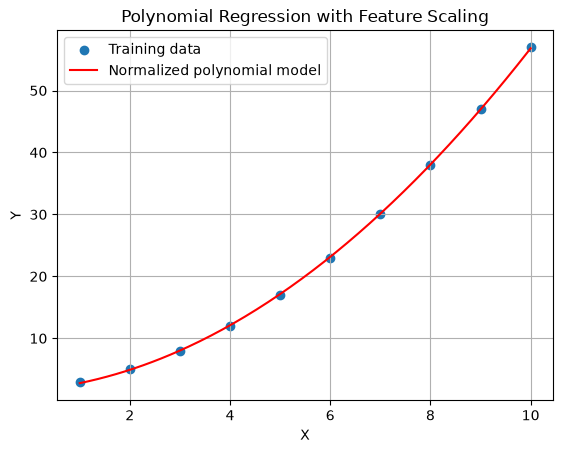

In [13]:
# Generate smooth x values
x_plot = np.linspace(x_train.min(), x_train.max(), 200)

# Create polynomial features
X_plot = np.column_stack((x_plot, x_plot**2))

# Apply the original training normalization parameters
X_plot_norm = (X_plot - mean) / std

# Predict using normalized weights
y_plot = compute_prediction(X_plot_norm, w_norm, b_norm)

# Plot
plt.scatter(x_train, y_train, label="Training data")
plt.plot(x_plot, y_plot, color="red", label="Normalized polynomial model")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression with Feature Scaling")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Predictions from the unscaled model
y_pred_unscaled = compute_prediction(x_poly, w_final, b_final)

# Predictions from the scaled model
y_pred_scaled = compute_prediction(X_poly_norm, w_norm, b_norm)

print("Actual values:     ", y_train[:5])
print("Unscaled predictions:", y_pred_unscaled[:5])
print("Scaled predictions:  ", y_pred_scaled[:5])

print("Unscaled cost:", compute_cost(x_poly, y_train, w_final, b_final))
print("Scaled cost:", compute_cost(X_poly_norm, y_train, w_norm, b_norm))

Actual values:      [ 3  5  8 12 17]
Unscaled predictions: [ 0.97994802  2.94599342  6.01422713 10.18464918 15.45725954]
Scaled predictions:   [ 2.76220474  4.91046041  8.02293648 12.09963294 17.14054979]
Unscaled cost: 1.096389930771816
Scaled cost: 0.008558053041969929


In [15]:
w_new=w_norm/std
b_new=b_norm-((w_norm[0]*mean[0])/std[0])-(w_norm[1]*mean[1])/std[1]
print("w: ",w_new)
print("b: ",b_new)

w:  [0.70192508 0.4821102 ]
b:  1.5781694689151244


In [16]:
y_pred_converted = compute_prediction(x_poly, w_new, b_new)

print("Normalized predictions:", y_pred_scaled[:5])
print("Converted predictions:", y_pred_converted[:5])

print("Maximum prediction difference:",
      np.max(np.abs(y_pred_scaled - y_pred_converted)))

Normalized predictions: [ 2.76220474  4.91046041  8.02293648 12.09963294 17.14054979]
Converted predictions: [ 2.76220474  4.91046041  8.02293648 12.09963294 17.14054979]
Maximum prediction difference: 1.4210854715202004e-14


Section: Ridge Regression (L2 Regularization)

In [17]:
def compute_cost_reg(x,y,w,b,lambda_):
    m=x.shape[0]
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    cost=np.sum(error**2)/(2*m)

    weight=np.sum(w**2)
    penality=(lambda_*weight)/(2*m)
    cost_reg= cost+penality
    return cost_reg

In [18]:
def compute_gradient_reg(x,y,w,b,lambda_):
    m=x.shape[0]
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    w_cost=(x.T@error)/m
    w_cost_reg=(lambda_*w)/m
    dj_dw = w_cost+w_cost_reg
    dj_db=(np.sum(y_pred-y))/m
    return dj_dw,dj_db

In [19]:
def gradient_descent_reg(x,y,w,b,alpha,iterations,lambda_):
    cost_history=[]
    for i in range(iterations):
        dj_dw,dj_db=compute_gradient_reg(x,y,w,b,lambda_)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        cost_history.append(compute_cost_reg(x,y,w,b,lambda_))
    return w,b,cost_history

Regularization is a technique used in machine learning to reduce overfitting by penalizing large model weights. It encourages the model to learn simpler patterns that generalize better to unseen data.
How lambda affects the model
- λ = 0: No regularization.
- Small λ: Weak penalty, allowing larger weights.
- Large λ: Strong penalty, pushing weights toward smaller values and potentially causing underfitting.
Why we use regularization
- Helps reduce overfitting.
- Controls model complexity.
- Can improve generalization to unseen data.
- May increase training prediction error because the model sacrifices some training fit to keep weights smaller.
Regularization doesn't guarantee that every individual weight will decrease compared with the original model. It penalizes the overall squared magnitude of the weights, and the model may redistribute weights between correlated features while optimizing its objective.

In [20]:
def create_polynomial_features(x, degree):
    if degree == 1:
        return np.column_stack([x])

    x_poly = np.column_stack([
        create_polynomial_features(x, degree - 1),
        x**degree
    ])

    return x_poly

In [21]:
x_all = np.arange(1, 11)
y_all = np.array([3, 5, 8, 12, 17, 23, 30, 38, 47, 57])

x_train, x_test, y_train, y_test = train_test_split(
    x_all, y_all, test_size=0.2, random_state=42
)

In [22]:
X_poly_train = create_polynomial_features(x_train, degree=2)
X_poly_test = create_polynomial_features(x_test, degree=2)

In [23]:
mean = np.mean(X_poly_train, axis=0)
std = np.std(X_poly_train, axis=0)

X_poly_train_norm = (X_poly_train - mean) / std
X_poly_test_norm = (X_poly_test - mean) / std

In [24]:
lambda_values = [0, 1, 100]
results = []

for lam in lambda_values:
    w_init = np.zeros(X_poly_train_norm.shape[1])
    b_init = 0

    w_model, b_model, cost_history = gradient_descent_reg(
        X_poly_train_norm, y_train,
        w_init, b_init,
        alpha=0.01,
        iterations=10000,
        lambda_=lam
    )

    test_cost = compute_cost(
        X_poly_test_norm, y_test, w_model, b_model
    )

    results.append((lam, w_model, b_model, test_cost))

    print(f"\nLambda: {lam}")
    print("Weights:", w_model)
    print("Bias:", b_model)
    print("Test prediction cost:", test_cost)


Lambda: 0
Weights: [ 1.60238729 15.05933731]
Bias: 23.499999999999826
Test prediction cost: 0.0009343060742751132

Lambda: 1
Weights: [6.3723921  9.29374505]
Bias: 23.499999999999826
Test prediction cost: 1.0191248269384905

Lambda: 100
Weights: [1.11425526 1.15109627]
Bias: 23.499999999999822
Test prediction cost: 166.56481094811474


In [25]:
rng = np.random.default_rng(42)

x_all = np.linspace(0, 10, 40)

noise = rng.normal(0, 5, size=40)

y_all = 0.5 * x_all**2 + 1.5 * x_all + 1 + noise

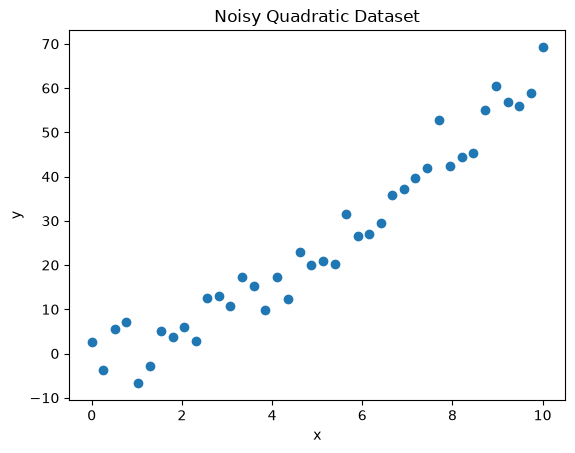

In [26]:
plt.scatter(x_all, y_all)
plt.title("Noisy Quadratic Dataset")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [27]:
x_train,x_test,y_train,y_test=train_test_split(x_all,y_all,test_size=0.2, random_state=42)

In [28]:
X_poly_train = create_polynomial_features(x_train, degree=8)
X_poly_test = create_polynomial_features(x_test, degree=8)

In [29]:
mean = np.mean(X_poly_train, axis=0)
std = np.std(X_poly_train, axis=0)

X_poly_train_norm = (X_poly_train - mean) / std
X_poly_test_norm = (X_poly_test - mean) / std

In [30]:
w = np.zeros(X_poly_train_norm.shape[1])
b = 0

alpha = 0.01
iterations = 10000
w, b, cost_history = gradient_descent(
    X_poly_train_norm, y_train, w, b, alpha, iterations
)

In [31]:
train_cost = compute_cost(X_poly_train_norm, y_train, w, b)
test_cost = compute_cost(X_poly_test_norm, y_test, w, b)

print("Train cost:", train_cost)
print("Test cost:", test_cost)

Train cost: 7.907889613580952
Test cost: 9.838048091737933


In [32]:
X_poly_all = create_polynomial_features(x_all, degree=8)
X_poly_all_norm = (X_poly_all - mean) / std

y_pred_all = compute_prediction(X_poly_all_norm, w, b)

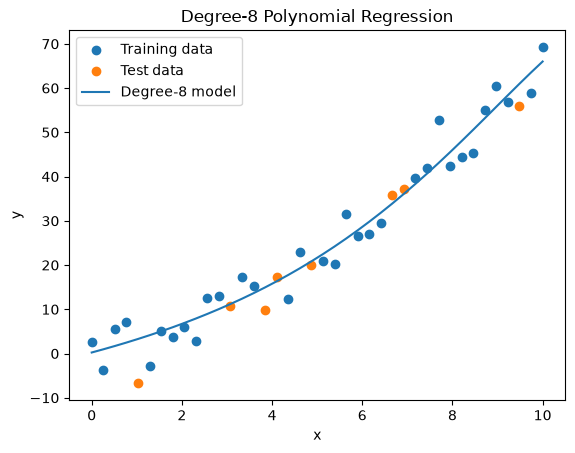

In [33]:
plt.scatter(x_train, y_train, label="Training data")
plt.scatter(x_test, y_test, label="Test data")
plt.plot(x_all, y_pred_all, label="Degree-8 model")

plt.title("Degree-8 Polynomial Regression")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

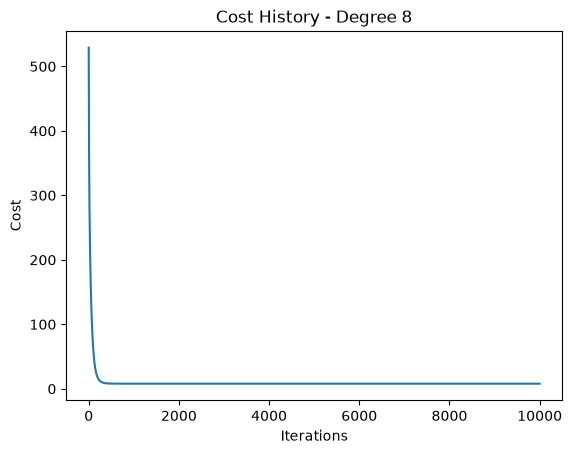

In [35]:
plt.plot(cost_history)
plt.title("Cost History - Degree 8")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.show()

In [47]:
# apply regularization
lambda_ = 1

w_reg = np.zeros(X_poly_train_norm.shape[1])
b_reg = 0

w_reg, b_reg, cost_history_reg = gradient_descent_reg(
    X_poly_train_norm,
    y_train,
    w_reg,
    b_reg,
    alpha=0.01,
    iterations=10000,
    lambda_=lambda_
)

In [49]:
train_cost_reg = compute_cost(
    X_poly_train_norm, y_train, w_reg, b_reg
)

test_cost_reg = compute_cost(
    X_poly_test_norm, y_test, w_reg, b_reg
)

print("Regularized train cost:", train_cost_reg)
print("Regularized test cost:", test_cost_reg)

Regularized train cost: 7.99470951592534
Regularized test cost: 10.818965514458135


Experimental results:

Model                                Without regularization                     With regularization (lambda=1)

Training Cost                        7.9079                                     7.9947

Test Cost                            9.8380                                     10.8189

The model without regularization performed better in this experiment because it achieved a lower test cost. This does not mean L2 regularization is ineffective. It means regularization does not always improve performance, especially when the original model is not strongly overfitting.

The purpose of regularization is to reduce overfitting and improve generalization, not simply to reduce the cost.